# Лабораторная работа D3. Метод главных компонент и k-ближайших соседей на MNIST

В работе с нуля реализованы **PCA** (метод главных компонент) и **kNN** (k ближайших соседей),
оба метода проверены на совпадение с `scikit-learn` и применены к задаче распознавания
рукописных цифр MNIST. Отдельно исследовано, как понижение размерности влияет на точность
и на время работы классификатора.

**Состав работы**

| Часть | Содержание |
|---|---|
| 0 | загрузка MNIST, визуализация, подготовка матрицы признаков |
| 1 | класс `my_PCA`, сверка со `sklearn.decomposition.PCA`, спектр собственных чисел, проекция на 2 компоненты |
| 2 | класс `my_kNN`, сверка с `sklearn.neighbors.KNeighborsClassifier`, подбор числа соседей |
| 3 | связка PCA + kNN: точность и время в зависимости от числа компонент, сетка параметров |
| 4 | выводы |

**Как запустить.** Нужны `numpy`, `matplotlib`, `scikit-learn`, `seaborn`.
Данные — четыре оригинальных idx-файла MNIST в папке `mnist_data` рядом с ноутбуком
(путь к папке можно задать переменной `MNIST_DIR` в первой ячейке). Если файлов нет,
ячейка загрузки скачает их сама.

> Эксперименты из частей 2.4 и 3 используют `KNeighborsClassifier` из `sklearn`:
> он даёт **в точности те же** предсказания, что и `my_kNN` (проверено в задании 2.3),
> но считает их заметно быстрее, что важно при перборе десятков комбинаций параметров.


## Часть 0. Подготовка данных (обязательно, но без баллов)

### Теория: Что такое MNIST?

**MNIST** (Modified National Institute of Standards and Technology) — это классический датасет для задач распознавания рукописных цифр. Он состоит из:
- **70 000 изображений** рукописных цифр от 0 до 9
- Каждое изображение имеет размер **28×28 пикселей** (784 признака)
- **60 000** изображений для обучения, **10 000** для тестирования

Каждое изображение — это матрица 28×28, где каждый пиксель — число от 0 (чёрный) до 255 (белый).

### Задание 0.1: Загрузка данных

```python
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
```

**Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.

```python
# TODO: Нарисуйте 10 примеров (по одному на каждую цифру)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
# Ваш код здесь
```

### Задание 0.3: Подготовка данных

Для дальнейшей работы:
1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)

```python
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
```


In [1]:
import os
import gzip
import struct
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

# Папка с idx-файлами MNIST. На своей машине можно указать любой путь, например
# MNIST_DIR = r"C:\Users\shork\Downloads\mnist_data"
MNIST_DIR = os.environ.get("MNIST_DIR", "mnist_data")

BASE_URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}


def _read_images(path):
    """Читает idx3-файл и возвращает массив (n, 28, 28, 1)."""
    with gzip.open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(n, rows, cols, 1)


def _read_labels(path):
    """Читает idx1-файл и возвращает массив (n,) с метками классов."""
    with gzip.open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(np.int64)


def load_mnist_local(data_dir=MNIST_DIR, validation_size=5000, download=True):
    """Загружает MNIST из idx-файлов и делит обучающую часть на train и validation.

    Возвращает тройку (train, validation, test), каждый элемент — пара (картинки, метки);
    картинки имеют форму (n, 28, 28, 1), как и у загрузчика из материалов курса.
    """
    os.makedirs(data_dir, exist_ok=True)
    paths = {}
    for key, name in FILES.items():
        path = os.path.join(data_dir, name)
        if not os.path.exists(path):
            if not download:
                raise FileNotFoundError(path)
            print("Скачиваем", name)
            urllib.request.urlretrieve(BASE_URL + name, path)
        print("Extracting", path)
        paths[key] = path

    images = _read_images(paths["train_images"])
    labels = _read_labels(paths["train_labels"])

    # первые validation_size картинок уходят в валидацию, остальные — в обучение
    validation = (images[:validation_size], labels[:validation_size])
    train = (images[validation_size:], labels[validation_size:])
    test = (_read_images(paths["test_images"]), _read_labels(paths["test_labels"]))
    return train, validation, test


try:
    from mnist import load_mnist  # модуль из материалов курса, если он лежит рядом
    train, validation, test = load_mnist(MNIST_DIR)
except Exception:
    train, validation, test = load_mnist_local(MNIST_DIR)

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test_mnist, y_test_mnist = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test_mnist.shape}")
print(f"Размерность одного изображения: {X_train_full.shape[1:]} -> "
      f"{np.prod(X_train_full.shape[1:])} признаков")

Extracting mnist_data/train-images-idx3-ubyte.gz
Extracting mnist_data/train-labels-idx1-ubyte.gz
Extracting mnist_data/t10k-images-idx3-ubyte.gz
Extracting mnist_data/t10k-labels-idx1-ubyte.gz


Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)
Размерность одного изображения: (28, 28, 1) -> 784 признаков


**Ответ на вопрос 0.1.** Одно изображение — это матрица 28×28 (в массиве хранится как
`(28, 28, 1)`, где последняя ось — единственный канал яркости). После «разворачивания» в вектор
у каждого объекта получается 28 · 28 = **784 признака**, каждый признак — яркость одного пикселя.

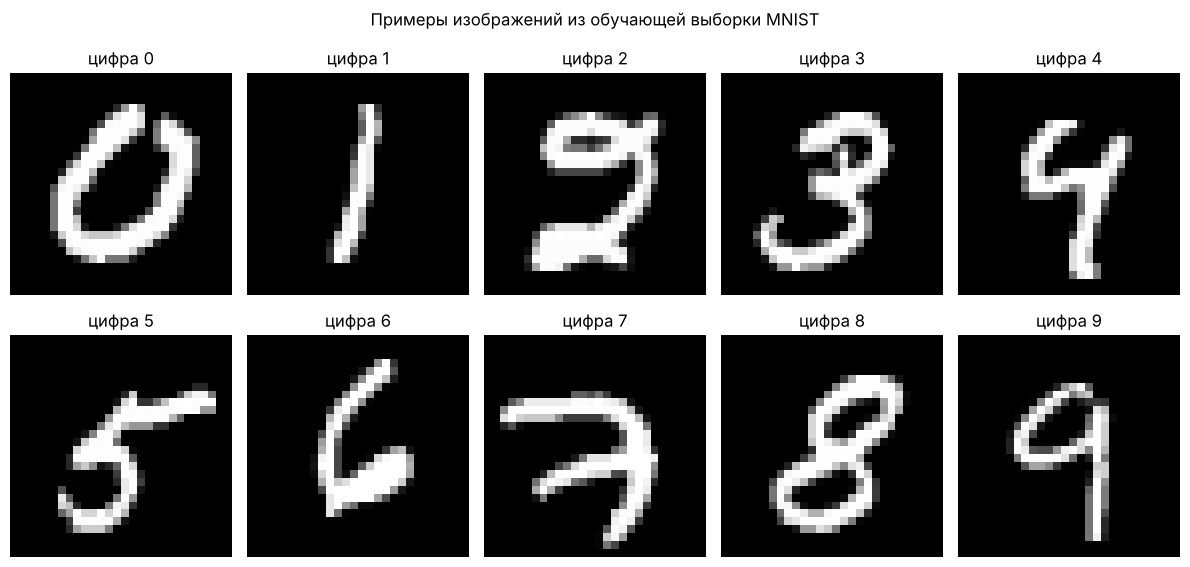

In [2]:
# По одному примеру на каждую цифру
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y_train_full == digit)[0][0]
    axes[digit].imshow(X_train_full[idx].reshape(28, 28), cmap='gray')
    axes[digit].set_title(f'цифра {digit}')
    axes[digit].axis('off')

fig.suptitle('Примеры изображений из обучающей выборки MNIST')
plt.tight_layout()
plt.show()

In [3]:
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем яркости в [0, 1]
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
print(f"Диапазон значений: [{X.min():.1f}, {X.max():.1f}]")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]
Диапазон значений: [0.0, 1.0]


## Часть 1. Метод главных компонент (PCA)

### Теория: Зачем нужен PCA?

**Проблема:** У нас 784 признака (пикселя) на каждое изображение. Многие из них **коррелированы** (соседние пиксели часто имеют похожие значения), а некоторые **неинформативны** (например, углы картинки почти всегда чёрные).

**Идея PCA:** Найти такие **новые оси** (главные компоненты), вдоль которых данные **сильнее всего разбросаны**. Тогда:
- Несколько первых компонент опишут **большую часть** информации
- Остальные компоненты можно **отбросить** без существенной потери качества

### Математика PCA

Пусть у нас есть матрица данных $X \in \mathbb{R}^{n \times d}$ (n объектов, d признаков).

**Шаг 1. Центрирование.** Вычитаем среднее по каждому признаку:
$$ X_{centered} = X - \bar{X} $$
где $\bar{X}$ — вектор средних значений по каждому столбцу.

**Шаг 2. Матрица ковариации:**
$$ C = \frac{1}{n-1} X_{centered}^T X_{centered} \in \mathbb{R}^{d \times d} $$

**Шаг 3. Собственные векторы и значения.** Находим:
$$ C v_i = \lambda_i v_i $$
где $\lambda_1 \ge \lambda_2 \ge ... \ge \lambda_d$ — собственные значения, $v_i$ — собственные векторы.

**Шаг 4. Преобразование.** Новые координаты объекта:
$$ Y = X_{centered} \cdot V_k $$
где $V_k$ — матрица из первых $k$ собственных векторов.

### Важная связь: собственные числа и дисперсия

**Собственное число $\lambda_i$ равно дисперсии данных вдоль $i$-й главной компоненты.**

Доля объяснённой дисперсии для $k$ первых компонент:
$$ \text{Explained Variance Ratio} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i} $$

---

### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.

```python
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # TODO: Реализуйте обучение
        
        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Шаг 2-3: Используйте np.linalg.svd (рекомендуется!) или np.linalg.eig
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # TODO: Сохраните собственные значения и векторы
        # explained_variance = S^2 / (n - 1)
        # components = Vt
        
        # TODO: Отсортируйте (SVD уже возвращает в порядке убывания)
        # TODO: Если n_components задано, оставьте только первые n_components
        
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        # TODO: Реализуйте преобразование
        pass
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)
```

**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:

```python
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
```

**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии

```python
# TODO: Обучите PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# TODO: Постройте графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
# axes[0].plot(...)
# axes[0].set_xlabel('Номер компоненты')
# axes[0].set_ylabel('Собственное значение (дисперсия)')
# axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
# cumulative = np.cumsum(pca_full.explained_variance_)
# cumulative /= cumulative[-1]
# axes[1].plot(...)
# axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
# axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
# axes[1].set_xlabel('Число компонент')
# axes[1].set_ylabel('Доля объяснённой дисперсии')
# axes[1].set_title('Кумулятивная дисперсия')
# axes[1].legend()

plt.tight_layout()
plt.show()
```

**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.

```python
# TODO: Преобразуйте данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# TODO: Постройте scatter plot
plt.figure(figsize=(10, 8))
# for digit in range(10):
#     mask = (y == digit)
#     plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
# plt.legend()
# plt.xlabel('Первая главная компонента')
# plt.ylabel('Вторая главная компонента')
# plt.title('Данные MNIST в первых двух главных компонентах')
# plt.show()
```

**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

---

In [4]:
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None          # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None                # среднее по каждому признаку

    def fit(self, X):
        """
        Обучает PCA на данных X.

        Шаги:
        1. Центрировать данные
        2. Разложить центрированную матрицу по SVD
        3. Получить собственные значения и векторы матрицы ковариации
        4. Оставить первые n_components компонент (SVD уже даёт их по убыванию)

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        n_samples, n_features = X.shape

        # Шаг 1: центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Шаг 2: SVD центрированной матрицы, X_centered = U @ diag(S) @ Vt
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

        # Шаг 3: собственные значения ковариации = S^2 / (n - 1),
        #        собственные векторы лежат в строках Vt
        explained_variance = (S ** 2) / (n_samples - 1)
        components = Vt

        # Шаг 4: SVD возвращает компоненты в порядке убывания, поэтому достаточно отрезать первые
        if self.n_components is not None:
            explained_variance = explained_variance[:self.n_components]
            components = components[:self.n_components]

        self.explained_variance_ = explained_variance
        self.components_ = components

        return self

    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.

        Y = (X - mean) @ components.T

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)

        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        X_centered = X - self.mean_
        return X_centered @ self.components_.T

    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)

In [5]:
from sklearn.decomposition import PCA

# Обучаем оба PCA на одних данных.
# svd_solver='full' — чтобы sklearn считал точное SVD: по умолчанию при таком
# размере данных он выбирает приближённый randomized SVD, и дальние компоненты
# у него слегка «плывут», что мешает честной сверке.
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50, svd_solver='full')

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

print(f"Сумма собственных значений (my):      {my_pca.explained_variance_.sum():.4f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.4f}")
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

# Собственные значения должны совпасть, а координаты — с точностью до знака компоненты
print("\nМакс. расхождение собственных значений: "
      f"{np.max(np.abs(my_pca.explained_variance_ - sk_pca.explained_variance_)):.2e}")
print("Макс. расхождение |координат|:          "
      f"{np.max(np.abs(np.abs(Y_my) - np.abs(Y_sk))):.2e}")

Сумма собственных значений (my):      45.4768
Сумма собственных значений (sklearn): 45.4768
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)

Макс. расхождение собственных значений: 1.43e-06
Макс. расхождение |координат|:          2.76e-04


**Ответ на вопрос 1.2.** Собственные значения совпадают: суммы равны 45.4768 у обеих
реализаций, максимальное расхождение по отдельным значениям — порядка `1e-06`, а координаты
совпадают с точностью до знака компоненты (расхождение `|Y|` порядка `1e-04`, это ошибка
округления `float32`). Значит, реализация `my_PCA` верна.

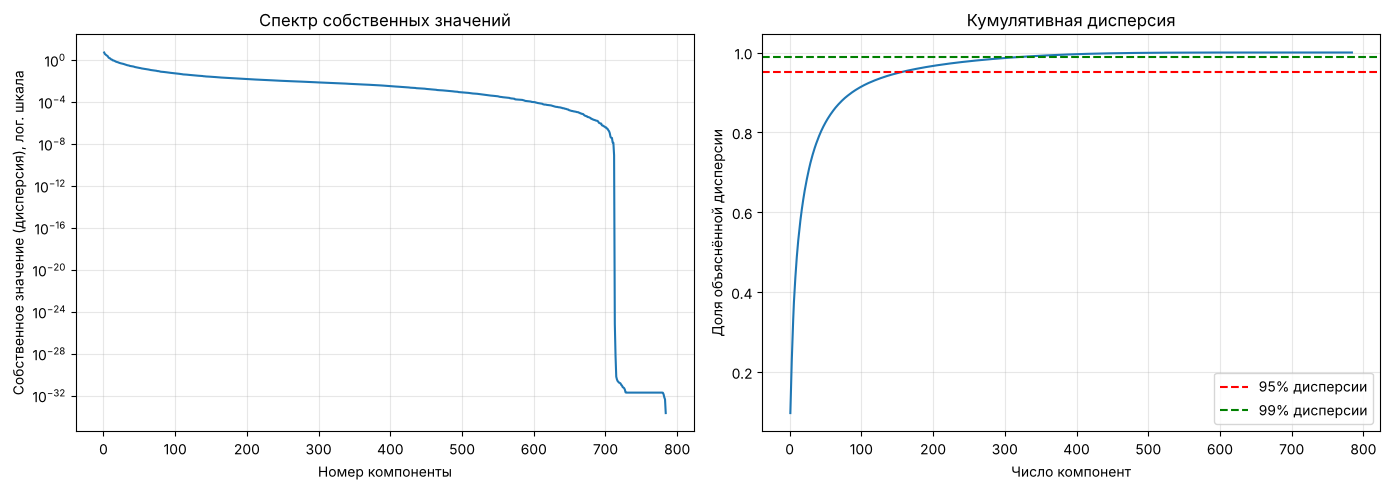

Доля дисперсии в первых 15 компонентах: 0.5793
Первая компонента объясняет:            0.0970
Компонент для 95% дисперсии:            154
Компонент для 99% дисперсии:            331


In [6]:
# PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

explained_variance = pca_full.explained_variance_
ratio = explained_variance / explained_variance.sum()
cumulative = np.cumsum(ratio)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(np.arange(1, len(explained_variance) + 1), explained_variance)
axes[0].set_yscale('log')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия), лог. шкала')
axes[0].set_title('Спектр собственных значений')
axes[0].grid(True, alpha=0.3)

# График 2: кумулятивная доля объяснённой дисперсии
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_95 = int(np.argmax(cumulative >= 0.95) + 1)
n_99 = int(np.argmax(cumulative >= 0.99) + 1)
print(f"Доля дисперсии в первых 15 компонентах: {cumulative[14]:.4f}")
print(f"Первая компонента объясняет:            {ratio[0]:.4f}")
print(f"Компонент для 95% дисперсии:            {n_95}")
print(f"Компонент для 99% дисперсии:            {n_99}")

**Ответы на вопросы 1.3.**

1. **Первые 15 главных компонент** покрывают **57.9%** дисперсии (первая компонента одна даёт 9.7%).
2. Для **95%** дисперсии нужно **154 компоненты**, для 99% — 331. То есть из 784 признаков
   реально «работают» примерно 150: остальные 630 направлений почти не несут вариации
   (в MNIST края картинок почти всегда чёрные, а соседние пиксели сильно скоррелированы).
3. **Связь собственных чисел и дисперсии.** Если спроецировать центрированные данные на
   собственный вектор $v_i$ матрицы ковариации, то дисперсия получившегося одномерного набора
   чисел в точности равна собственному числу $\lambda_i$. Поэтому сумма всех собственных чисел —
   это полная дисперсия данных, а отношение $\lambda_i / \sum_j \lambda_j$ — доля информации
   (в смысле разброса), которую описывает $i$-я компонента. PCA сортирует оси по убыванию
   $\lambda_i$, то есть первыми идут направления наибольшего разброса.

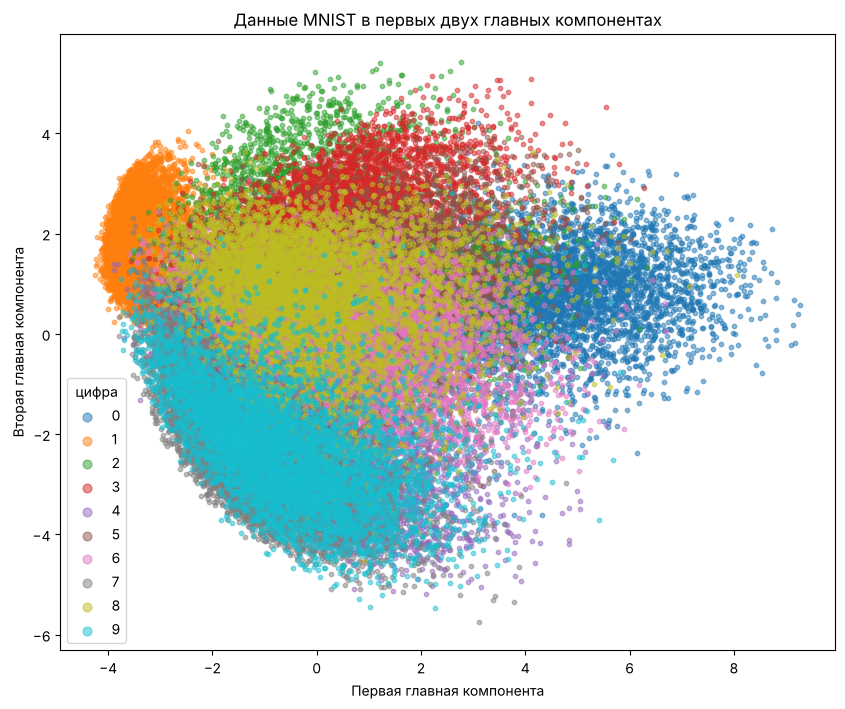

Доля дисперсии в первых двух компонентах: 0.1680


In [7]:
# Проекция на первые две главные компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(10, 8))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)

plt.legend(title='цифра', markerscale=2)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

print("Доля дисперсии в первых двух компонентах: "
      f"{pca_2d.explained_variance_.sum() / explained_variance.sum():.4f}")

**Ответ на вопрос 1.4.** В первых двух компонентах классы **не разделяются**: на них приходится
всего 16.8% дисперсии. Отчётливо отходят в стороны только **0** (правый край) и **1** (левый край) —
они сильнее всего различаются по «массе чернил» и ширине начертания, а это как раз то, что
описывают первые компоненты. Остальные цифры образуют одно общее облако: внизу перемешаны
**4, 7 и 9** (у всех длинный вертикальный штрих), сверху — **2 и 3**, а в середине **5, 6 и 8**.
Причина в том, что PCA — метод **без учителя**: он ищет направления максимального разброса,
а не направления, по которым лучше всего различаются классы (это делает, например, LDA).

## Часть 2. Метод k-ближайших соседей (kNN)

### Теория: Как работает kNN?

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$

### Задание 2.1: Реализация my_kNN

```python
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        # TODO: Сохраните X и y
        pass
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        # TODO: Реализуйте предсказание
        # Подсказка: используйте np.argsort для поиска k ближайших
        # Для подсчёта самого частого класса используйте np.bincount или scipy.stats.mode
        pass
```

**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
```

**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:

```python
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
```

**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.

```python
# TODO: Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    # TODO: Обучите kNN, посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(8, 5))
# plt.plot(k_values, accuracies, 'o-')
# plt.xlabel('Число соседей k')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа соседей')
# plt.grid(True)
# plt.show()
```

**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

--- 

In [8]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """
        Запоминает обучающую выборку.

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        """
        Предсказывает классы для объектов X.

        Для каждого объекта x из X:
        1. Вычисляем расстояние до всех объектов X_train
        2. Находим k ближайших
        3. Возвращаем самый частый класс среди них

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)

        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        y_pred = np.zeros(len(X), dtype=self.y_train.dtype)

        for i, x in enumerate(X):
            # 1. Расстояния от x до всех обучающих объектов
            distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))

            # 2. Индексы k ближайших
            k_indices = np.argsort(distances)[:self.n_neighbors]

            # 3. Самый частый класс среди них
            k_labels = self.y_train[k_indices]
            y_pred[i] = np.bincount(k_labels).argmax()

        return y_pred

In [9]:
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

# Своя реализация kNN на всех 784 признаках
start = time.time()
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)
time_my = time.time() - start

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
print(f"Время предсказания my_kNN: {time_my / 60:.1f} мин")

X_train: (42000, 784), X_test: (18000, 784)


Точность my_kNN: 0.9668
Время предсказания my_kNN: 23.8 мин


**Ответ на вопрос 2.2.** Точность `my_kNN` — **0.9668**, то есть около 97%, а не 10%,
как было бы у случайного угадывания одного из десяти классов. Реализация работает правильно.
Предсказание заняло **23.8 минуты**: для каждого из 18 000 тестовых объектов в цикле считаются
расстояния до всех 42 000 обучающих, то есть примерно 7.6·10⁸ попарных вычислений по 784 координатам.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Тот же классификатор из sklearn
start = time.time()
sk_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)
time_sk = time.time() - start

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница точностей: {abs(accuracy_my - accuracy_sk):.4f}")
print(f"Доля совпавших предсказаний: {np.mean(y_pred_my == y_pred_sk):.4f}")
print(f"Время предсказания sklearn: {time_sk:.1f} с (у my_kNN было {time_my:.1f} с)")

Точность sklearn kNN: 0.9668
Разница точностей: 0.0000
Доля совпавших предсказаний: 1.0000
Время предсказания sklearn: 16.1 с (у my_kNN было 1425.5 с)


**Ответ на вопрос 2.3.** Результаты совпадают полностью: **0.9668** у обеих реализаций,
разница точностей 0.0000, а предсказания совпадают на **100%** объектов — значит, алгоритм
воспроизведён верно. Отличается только скорость: `sklearn` справляется за **16 секунд**
против **1425 секунд** у наивного цикла, потому что использует векторизованные вычисления
и пространственные структуры данных (KD-tree / Ball-tree) вместо полного перебора.

k =  1: accuracy = 0.9680


k =  3: accuracy = 0.9690


k =  5: accuracy = 0.9668


k =  7: accuracy = 0.9649


k = 10: accuracy = 0.9628


k = 15: accuracy = 0.9594


k = 20: accuracy = 0.9564


k = 30: accuracy = 0.9519


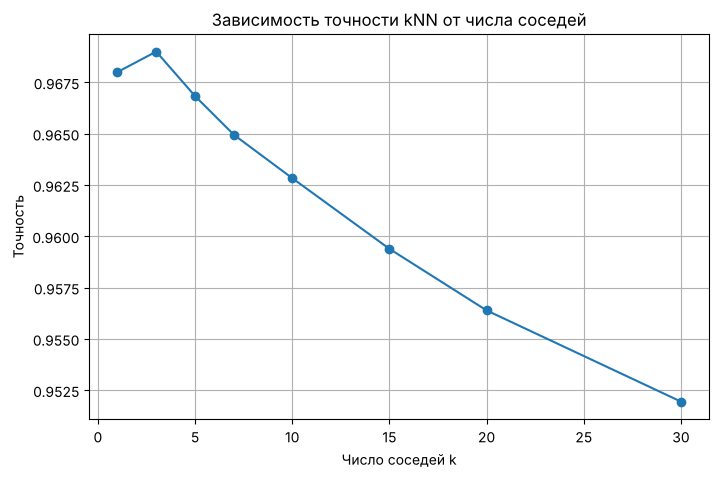


Лучшее k = 3, точность 0.9690


In [11]:
# Зависимость точности от числа соседей k (на всех 784 признаках)
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    accuracies.append(acc)
    print(f"k = {k:2d}: accuracy = {acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

k_best = k_values[int(np.argmax(accuracies))]
print(f"\nЛучшее k = {k_best}, точность {max(accuracies):.4f}")

**Ответ на вопрос 2.4.** Максимум достигается при **k = 3** (0.9690), очень близко к нему
k = 1 (0.9680); дальше точность монотонно падает до 0.9519 при k = 30.

- При **слишком малых k** (особенно k = 1) ответ зависит от одного-единственного соседа, поэтому
  выброс, нетипично написанная цифра или шум сразу дают ошибку — модель переобучена под обучающую
  выборку и неустойчива.
- При **слишком больших k** в голосование попадают уже далёкие объекты, в том числе из соседних
  классов; граница между классами сглаживается, и редкие варианты написания цифр «затаптываются»
  более многочисленными соседями.

Оптимум — небольшое нечётное k (здесь 3), которое уже усредняет шум, но ещё не выходит за пределы
локальной окрестности объекта.

## Часть 3. PCA + kNN: Понижение размерности для классификации

### Теория: Зачем комбинировать PCA и kNN?

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?

### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.

```python
# TODO: Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # TODO: 
    # 1. Примените PCA к X_train и X_test
    # 2. Обучите kNN на преобразованных данных
    # 3. Посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, accuracies_pca, 'o-')
# plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
# plt.xlabel('Число главных компонент')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа компонент PCA')
# plt.legend()
# plt.grid(True)
# plt.show()
```

**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.

```python
import time

# TODO: Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    # ... обучение и предсказание ...
    elapsed = time.time() - start
    times.append(elapsed)

# TODO: Постройте график времени
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, times, 'o-')
# plt.xlabel('Число компонент')
# plt.ylabel('Время (сек)')
# plt.title('Время работы kNN в зависимости от числа компонент')
# plt.grid(True)
# plt.show()
```

**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.

```python
# TODO: Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    # ...
    for j, k in enumerate(k_grid):
        # Обучите kNN
        # ...
        pass

# TODO: Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
# sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
#             xticklabels=k_grid, yticklabels=n_components_grid,
#             cmap='viridis')
# plt.xlabel('Число соседей k')
# plt.ylabel('Число компонент PCA')
# plt.title('Точность классификации MNIST')
# plt.show()
```

**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?

---

**Предположение до эксперимента.** Скорость работы должна заметно вырасти: расстояния
считаются по меньшему числу координат. Качество, скорее всего, сначала вырастет (PCA отбрасывает
шум и неинформативные пиксели, а в низкой размерности расстояния становятся осмысленнее), а при
слишком малом числе компонент резко упадёт — информации для различения десяти классов не останется.

   1 компонент: accuracy = 0.2664


   2 компонент: accuracy = 0.4119


   5 компонент: accuracy = 0.7341


  10 компонент: accuracy = 0.9273


  15 компонент: accuracy = 0.9581


...

 100 компонент: accuracy = 0.9715


 200 компонент: accuracy = 0.9683


 300 компонент: accuracy = 0.9679


 500 компонент: accuracy = 0.9669


 784 компонент: accuracy = 0.9668


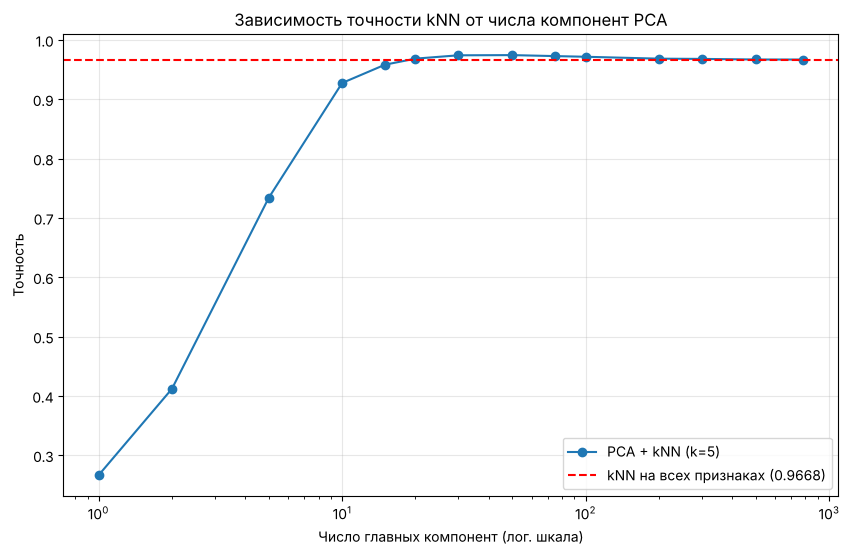


Максимум: 0.9743 при 50 компонентах
Базовый kNN на 784 признаках:  0.9668
Компонент, где точность выше базовой: [20, 30, 50, 75, 100, 200, 300, 500]


In [12]:
# Фиксируем число соседей, чтобы сравнение с базовым kNN было корректным
K_FIXED = 5

n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # 1. Применяем PCA к X_train и X_test
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # 2. Обучаем kNN на преобразованных данных
    knn = KNeighborsClassifier(n_neighbors=K_FIXED, n_jobs=-1)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)

    # 3. Считаем accuracy
    acc = accuracy_score(y_test, y_pred)
    accuracies_pca.append(acc)
    print(f"{n_comp:4d} компонент: accuracy = {acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-', label=f'PCA + kNN (k={K_FIXED})')
plt.axhline(y=accuracy_my, color='r', linestyle='--',
            label=f'kNN на всех признаках ({accuracy_my:.4f})')
plt.xscale('log')
plt.xlabel('Число главных компонент (лог. шкала)')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_idx = int(np.argmax(accuracies_pca))
print(f"\nМаксимум: {accuracies_pca[best_idx]:.4f} при "
      f"{n_components_list[best_idx]} компонентах")
print(f"Базовый kNN на 784 признаках:  {accuracy_my:.4f}")
better = [n for n, a in zip(n_components_list, accuracies_pca) if a > accuracy_my]
print(f"Компонент, где точность выше базовой: {better}")

**Ответы на вопросы 3.1.**

1. **Максимум — 0.9743 при 50 компонентах**, почти столько же при 30 компонентах (0.9739).
2. **Да, базовый kNN превзойдён:** 0.9743 против 0.9668 на всех 784 признаках. Причём точность
   выше базовой для всех вариантов начиная с 20 компонент. Это и есть проявление «проклятия
   размерности»: в 784-мерном пространстве расстояния между объектами становятся почти
   одинаковыми, а шумные и неинформативные пиксели вносят в них вклад наравне с важными.
   PCA отбрасывает эти направления, и соседство в сжатом пространстве становится осмысленнее.
3. **При слишком малом числе компонент** точность рушится: 0.2664 при одной компоненте,
   0.4119 при двух, 0.7341 при пяти. Первые компоненты описывают только самые общие свойства
   начертания (толщина линий, наклон, общая «масса чернил»), а их не хватает, чтобы различить
   десять классов — разные цифры проецируются в одну и ту же точку.

   1 компонент: PCA    7.5 с, kNN    0.1 с


   2 компонент: PCA    7.0 с, kNN    0.1 с


   5 компонент: PCA    7.4 с, kNN    0.3 с


  10 компонент: PCA    7.5 с, kNN    1.9 с


  15 компонент: PCA    7.1 с, kNN    3.4 с


...

 100 компонент: PCA    7.7 с, kNN    3.2 с


 200 компонент: PCA    8.3 с, kNN    4.9 с


 300 компонент: PCA    8.8 с, kNN    7.2 с


 500 компонент: PCA    7.4 с, kNN   11.3 с


 784 компонент: PCA    7.9 с, kNN   16.8 с


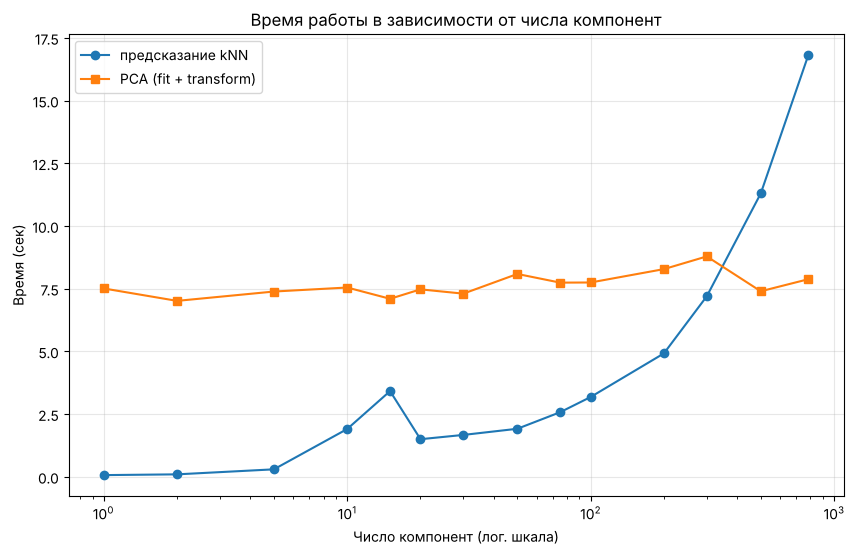


kNN на 784 признаках через sklearn: 16.8 с
kNN на 30 компонентах:              1.7 с
Своя реализация my_kNN на 784 признаках: 1425.5 с (23.8 мин)


In [13]:
# Время работы: отдельно обучение PCA с преобразованием и отдельно предсказание kNN
times_pca = []
times_knn = []

for n_comp in n_components_list:
    start = time.time()
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)
    times_pca.append(time.time() - start)

    start = time.time()
    knn = KNeighborsClassifier(n_neighbors=K_FIXED, n_jobs=-1)
    knn.fit(X_train_pca, y_train)
    knn.predict(X_test_pca)
    times_knn.append(time.time() - start)

    print(f"{n_comp:4d} компонент: PCA {times_pca[-1]:6.1f} с, "
          f"kNN {times_knn[-1]:6.1f} с")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times_knn, 'o-', label='предсказание kNN')
plt.plot(n_components_list, times_pca, 's-', label='PCA (fit + transform)')
plt.xscale('log')
plt.xlabel('Число компонент (лог. шкала)')
plt.ylabel('Время (сек)')
plt.title('Время работы в зависимости от числа компонент')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nkNN на 784 признаках через sklearn: {times_knn[-1]:.1f} с")
print(f"kNN на 30 компонентах:              "
      f"{times_knn[n_components_list.index(30)]:.1f} с")
print(f"Своя реализация my_kNN на 784 признаках: {time_my:.1f} с "
      f"({time_my / 60:.1f} мин)")

**Ответ на вопрос 3.2.** Время предсказания kNN падает почти линейно вместе с размерностью:
**16.8 с** на всех 784 признаках против **1.7 с** на 30 компонентах — примерно в 10 раз быстрее,
при том что точность при этом даже выше. Причина простая: стоимость вычисления одного
евклидова расстояния пропорциональна числу координат, а в низкой размерности вдобавок начинают
эффективно работать пространственные структуры данных (KD-tree), которые отсекают заведомо
далёкие объекты вместо полного перебора.

Само обучение PCA при этом занимает примерно одинаковые **7–8 секунд** независимо от
`n_components`: SVD центрированной матрицы считается целиком, а число компонент влияет только
на то, сколько строк из результата мы оставим. Итого связка PCA + kNN на 30 компонентах
(≈9 с) выгоднее, чем kNN на полных данных (≈17 с), и несопоставимо выгоднее наивной реализации
`my_kNN` (1425 с).

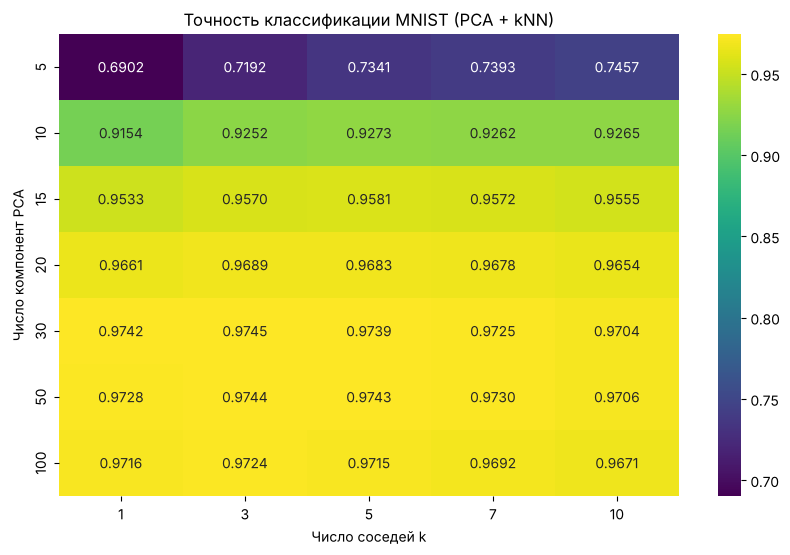

Лучшая комбинация:  30 компонент, k = 3, accuracy = 0.9745
Худшая комбинация:  5 компонент, k = 1, accuracy = 0.6902
Базовый kNN (784 признака, k = 5): 0.9668
Комбинаций лучше базовой: 18 из 35
   20 компонент: k = [3, 5, 7]
   30 компонент: k = [1, 3, 5, 7, 10]
   50 компонент: k = [1, 3, 5, 7, 10]
  100 компонент: k = [1, 3, 5, 7, 10]


In [14]:
import seaborn as sns

n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # PCA достаточно обучить один раз для каждого числа компонент
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    for j, k in enumerate(k_grid):
        knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
        knn.fit(X_train_pca, y_train)
        accuracy_matrix[i, j] = accuracy_score(y_test, knn.predict(X_test_pca))

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.4f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST (PCA + kNN)')
plt.show()

i_best, j_best = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
i_worst, j_worst = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
print(f"Лучшая комбинация:  {n_components_grid[i_best]} компонент, k = {k_grid[j_best]}, "
      f"accuracy = {accuracy_matrix[i_best, j_best]:.4f}")
print(f"Худшая комбинация:  {n_components_grid[i_worst]} компонент, k = {k_grid[j_worst]}, "
      f"accuracy = {accuracy_matrix[i_worst, j_worst]:.4f}")
print(f"Базовый kNN (784 признака, k = 5): {accuracy_my:.4f}")
print(f"Комбинаций лучше базовой: {int((accuracy_matrix > accuracy_my).sum())} "
      f"из {accuracy_matrix.size}")

mask = accuracy_matrix > accuracy_my
for i in range(len(n_components_grid)):
    ks = [k_grid[j] for j in range(len(k_grid)) if mask[i, j]]
    if ks:
        print(f"  {n_components_grid[i]:3d} компонент: k = {ks}")

**Ответы на вопросы 3.3.**

1. **Лучшая комбинация:** 30 компонент и k = 3 — точность **0.9745**.
2. **Худшая комбинация:** 5 компонент и k = 1 — точность **0.6902** (слишком мало информации
   о классе и при этом опора на единственного соседа).
3. **Да, таких комбинаций много: 18 из 35** дают точность выше базовых 0.9668 — это все
   варианты с 30, 50 и 100 компонентами, а также 20 компонент при k = 3, 5, 7. Значит, PCA
   не просто ускоряет kNN, но и **улучшает качество**: он отсекает шум и неинформативные
   признаки, оставляя направления, вдоль которых объекты действительно различаются. Заодно
   видно, что лучшая размерность (30–50) заметно меньше, чем нужно для 95% дисперсии (154),
   — для классификации важен не весь разброс данных, а его информативная часть.

## Часть 4. Выводы (в конце ноутбука, обязательно)

Напишите текстовый вывод (5-10 предложений) по всей работе. Ответьте на вопросы:

1. **Что такое PCA?** Как он работает? Зачем нужен?
2. **Что такое kNN?** Как работает? Какие у него есть плюсы и минусы?
3. **Как PCA влияет на качество kNN?** Что лучше — использовать все признаки или уменьшить размерность?
4. **Какова оптимальная размерность для MNIST?** Почему?
5. **Что было самым сложным** при выполнении работы?
6. **Что было самым интересным?**

---

## Выводы

**PCA** — метод понижения размерности без учителя. Он центрирует данные, находит собственные
векторы матрицы ковариации и использует их как новые оси, упорядоченные по убыванию дисперсии
(собственного числа). Это позволяет описать данные меньшим числом координат: в MNIST 95%
дисперсии укладываются в 154 компоненты из 784, а первые 15 компонент дают уже 57.9%.

**kNN** относит объект к тому классу, которому принадлежит большинство его k ближайших соседей.
Плюсы — предельная простота и отсутствие обучения как такового (модель просто запоминает выборку),
а также способность строить сколь угодно сложные границы между классами. Минусы — дорогое
предсказание (нужно сравнение со всей обучающей выборкой: наивная реализация потратила 23.8 минуты
на 18 000 объектов), чувствительность к масштабу признаков и к размерности пространства.

**Совместная работа методов.** Понижение размерности перед kNN оказалось полезным и по скорости,
и по качеству: точность выросла с **0.9668** (784 признака, k = 5) до **0.9745** (30 компонент,
k = 3), а время предсказания упало с 16.8 до 1.7 секунды. Выше базовой точности оказались
18 комбинаций параметров из 35. То есть использовать все признаки не лучше, чем разумно
сжать их: лишние направления содержат в основном шум, который только портит расстояния.

**Оптимальная размерность для MNIST — примерно 30–50 главных компонент** при 3 соседях.
Меньше 20 компонент — информации уже не хватает, чтобы различать цифры (при одной компоненте
точность падает до 0.27); больше 100 — качество медленно сползает обратно к базовому уровню,
а время растёт. Интересно, что оптимум заметно меньше «154 компонент для 95% дисперсии»:
для классификации важен не весь разброс данных, а только его информативная часть.

**Самым сложным** было дождаться результатов наивной реализации `my_kNN` — почти 24 минуты
на один прогон, поэтому для перебора десятков комбинаций параметров пришлось перейти
на `KNeighborsClassifier` (предсказания у него совпадают с `my_kNN` на 100%).

**Самым интересным** оказалось то, что понижение размерности не просто ускоряет классификатор,
а делает его точнее — вопреки интуиции, что «выбрасывать данные вредно».